In [1]:
import openseespy.opensees as ops
import opsvis as opsv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# unit conversion
m=1
mm=0.001*m
kn=1
pa=1
kpa=1000*pa
mpa=1000*kpa
gpa=1000*mpa

In [3]:
ops.wipe()
ops.model('basic', '-ndm', 2, '-ndf', 3)

In [4]:
# define steel material
mattag=1
fy=350*mpa
E=200*gpa
b=0.001
ops.uniaxialMaterial('Steel02', mattag, fy, E, b)

In [5]:
# define concrete material
fpc=-30*mpa
epsc0=-0.002
fpcu=-20*mpa
epsu=-0.008
lamda=0.1
ft=3*mpa
ets=150*mpa
ops.uniaxialMaterial('Concrete02', 2, fpc, epsc0, fpcu, epsu, lamda, ft, ets)
ops.uniaxialMaterial('Concrete02',3,
                    -25*mpa,
                    -0.002,
                    -15*mpa,
                    -0.006,
                    0.1,
                    2*mpa,
                    100*mpa)

In [6]:
ops.node(1, 0.0,0.0)
ops.node(2, 0.0,1)
ops.node(3, 0.0,2)
ops.node(4, 0.0,3)
ops.fix(1, 1, 1, 1)

In [7]:
# def getsection():
#section defination
# Bd=400*mm
# D=600*mm
confinedconcretetag=2
unconfinedconcretetag=3
numsubdiv=10
sectag=1
ops.section('Fiber', sectag, '-GJ', 1.0e6)
ops.patch('rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2) #CONFINED CONCRETE

ops.patch('quad',unconfinedconcretetag,1,1,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2) #unconfined concrete
ops.layer('straight', mattag, 3,300*mm**2,450*mm/2,300*mm/2,450*mm/2,-300*mm/2) #steel layer
ops.layer('straight', mattag, 3,300*mm**2,-450*mm/2,300*mm/2,-450*mm/2,-300*mm/2) #steel layer
#geometry transformation
ops.geomTransf('PDelta', 1)
ops.beamIntegration('Lobatto', 1, sectag, 2)
mass=6000

ops.element('forceBeamColumn', 1, 1, 2, 1, 1,'-mass',mass) #ops.element('forceBeamColumn', eleTag, iNode, jNode, transfTag, integrationTag, '-mass', massDensity)
ops.element('forceBeamColumn', 2, 2, 3, 1, 1,'-mass',mass)
ops.element('forceBeamColumn', 3, 3, 4, 1, 1,'-mass',mass)
# def plot():
fib_sec_1 = [
    ['section', 'Fiber', 1, '-GJ', 1.0e6],
    ['patch','rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2],
    ['patch','quad',unconfinedconcretetag,1,2,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2],   # right cover (यो थपियो)
    ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2],  # top cover
    ['patch','quad',unconfinedconcretetag,1,2,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2], # left cover
    ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2], # bottom cover
    ['layer', 'straight', mattag, 3, 300*mm**2, 450*mm/2,300*mm/2,450*mm/2,-300*mm/2],
    ['layer', 'straight', mattag, 3, 300*mm**2, -450*mm/2,300*mm/2,-450*mm/2,-300*mm/2]
]

In [8]:
controlNode = 4
controlNodeDof = 1
linearSeriesTag = 3

#time series
ops.timeSeries('Linear',linearSeriesTag)

#load pattern
ops.pattern('Plain',4, linearSeriesTag)
#now apply the load to the control node
ops.load(controlNode, *[1000, 0.0, 0.0])

    #analysis commands
ops.constraints("Transformation")
ops.numberer("Plain")
ops.system("BandGeneral")

ops.algorithm("Newton")
#integrator('DisplacementControl', nodeTag, dof, incr, numIter=1, dUmin=incr, dUmax=incr)

#ops.test('NormDispIncr', tol, iter, pFlag=0, nType=2)
ops.test('NormDispIncr', 1.0e-6, 50)
ops.analysis("Static")

WARNING analysis Static - no Integrator specified, 
 StaticIntegrator default will be used


In [9]:
BaseShear = []
Displacement = []
for i in range(1, 60):
    ops.integrator('DisplacementControl', controlNode, controlNodeDof, 0.001*(-1)**(i+1))
    for j in range(1*i):
        ops.analyze(1)
        Displacement.append(ops.nodeDisp(controlNode, controlNodeDof))
        BaseShear.append(-ops.eleForce(1, controlNodeDof))

In [10]:
BaseShear

[13616.175185642822,
 -21.55401612632932,
 -19700.591346261477,
 15.736071076537993,
 19712.859950666392,
 33597.32135668479,
 16593.70626273067,
 -64.24083691357421,
 -19762.58192313318,
 -33622.84670771151,
 -16629.91419142433,
 12.93926100667969,
 16822.7002967803,
 33614.55092158236,
 43174.955920313085,
 28529.17645203368,
 13883.406020577913,
 -68.5731270530007,
 -16856.993998908933,
 -33634.95112645133,
 -43183.40677768957,
 -28546.366818106413,
 -13909.336431411582,
 16.117880128686217,
 14392.369599273738,
 28801.08293019647,
 43176.443867834794,
 51027.78845499175,
 37980.0856529904,
 24932.56370452904,
 11884.943150124267,
 -60.33357492618789,
 -14402.421616200367,
 -28787.934251849296,
 -43078.02351508994,
 -50938.636984732555,
 -37922.64475914857,
 -24906.844288063956,
 -11890.942768992576,
 16.736383483655942,
 12723.190867735695,
 25484.207080120235,
 38245.22207814308,
 50920.548189588524,
 56834.71500339613,
 45178.05153700617,
 33519.516149541036,
 21861.618509187607,

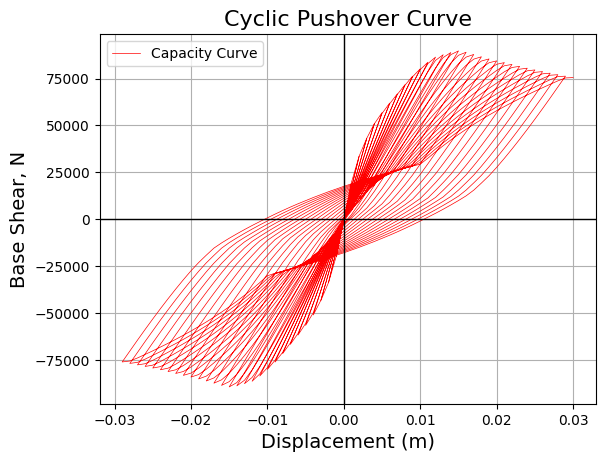

In [11]:

plt.plot(Displacement, BaseShear, zorder = 2, linewidth= 0.5, label=f'Capacity Curve', color='red')
# Customize title and axis labels with fontsize
plt.title('Cyclic Pushover Curve', fontsize=16)  # Set title size
plt.xlabel('Displacement (m)', fontsize=14)  # Set x-axis label size
plt.ylabel('Base Shear, N', fontsize=14)  # Set y-axis label size

# Customize tick label size
plt.xticks(fontsize=10)  # Set x-axis tick label size
plt.yticks(fontsize=10)  # Set y-axis tick label size

plt.axhline(0, color='black',linewidth=1)
plt.axvline(0, color='black',linewidth=1)
    
plt.grid(True)
        
plt.legend(fontsize=10)
        
plt.show()